In [6]:
%pip install seaborn
import pandas as pd
import numpy as np                       
import seaborn as sns                    
import matplotlib.pyplot as plt          

import sklearn                           
%matplotlib inline
sns.set(color_codes=True)

Note: you may need to restart the kernel to use updated packages.


In [7]:
full_data=pd.read_csv(r'C:\Users\USER\Downloads\WHO-COVID-19-global-daily-data.csv') 
print(full_data.columns.tolist())

['Date_reported', 'Country_code', 'Country', 'WHO_region', 'New_cases', 'Cumulative_cases', 'New_deaths', 'Cumulative_deaths']


In [8]:
full_data.shape            #tells no of rows and columns

(472560, 8)

In [9]:
full_data.head()                 #returns first 5 entries of dataset

,Date_reported,Country_code,Country,WHO_region,New_cases,Cumulative_cases,New_deaths,Cumulative_deaths
0,01/04/2020,VC,Saint Vincent and the GreNAMdines,AMR,NaN,0,NaN,0
1,01/04/2020,SN,Senegal,AFR,NaN,0,NaN,0
2,01/04/2020,SB,Solomon Islands,WPR,0.0,0,0.0,0
3,01/04/2020,LK,Sri Lanka,SEAR,0.0,0,0.0,0
4,01/04/2020,SY,Syrian Arab Republic,EMR,NaN,0,NaN,0


In [10]:
full_data.tail()          

,Date_reported,Country_code,Country,WHO_region,New_cases,Cumulative_cases,New_deaths,Cumulative_deaths
472555,5/25/2025,MX,Mexico,AMR,NaN,7622513,NaN,334818
472556,5/25/2025,MR,Mauritania,AFR,NaN,63889,NaN,997
472557,5/25/2025,ML,Mali,AFR,NaN,33193,NaN,743
472558,5/25/2025,ME,Montenegro,EUR,NaN,251280,NaN,2654
472559,5/25/2025,NC,New Caledonia,WPR,NaN,80203,NaN,314


In [11]:
full_data.count()                  #shows the count of non null values

Date_reported        472560
Country_code         472560
Country              472560
WHO_region           472560
New_cases            209256
Cumulative_cases     472560
New_deaths           153448
Cumulative_deaths    472560
dtype: int64

In [12]:
full_data.dtypes 

Date_reported            str
Country_code             str
Country                  str
WHO_region               str
New_cases            float64
Cumulative_cases       int64
New_deaths           float64
Cumulative_deaths      int64
dtype: object

In [13]:
full_data.info()      

<class 'pandas.DataFrame'>
RangeIndex: 472560 entries, 0 to 472559
Data columns (total 8 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Date_reported      472560 non-null  str    
 1   Country_code       472560 non-null  str    
 2   Country            472560 non-null  str    
 3   WHO_region         472560 non-null  str    
 4   New_cases          209256 non-null  float64
 5   Cumulative_cases   472560 non-null  int64  
 6   New_deaths         153448 non-null  float64
 7   Cumulative_deaths  472560 non-null  int64  
dtypes: float64(2), int64(2), str(4)
memory usage: 40.8 MB


In [14]:
full_data.isnull().sum()           #shows the number of null values in each column

Date_reported             0
Country_code              0
Country                   0
WHO_region                0
New_cases            263304
Cumulative_cases          0
New_deaths           319112
Cumulative_deaths         0
dtype: int64

In [15]:
full_data.describe()    

,New_cases,Cumulative_cases,New_deaths,Cumulative_deaths
count,2.092560e+05,4.725600e+05,153448.000000,4.725600e+05
mean,3.717696e+03,2.001990e+06,46.247915,2.139459e+04
std,4.868857e+04,8.405211e+06,242.756418,8.597986e+04
min,-6.507900e+04,0.000000e+00,-3520.000000,0.000000e+00
25%,3.000000e+00,6.265000e+03,0.000000,3.800000e+01
50%,6.100000e+01,5.714900e+04,2.000000,6.810000e+02
75%,6.840000e+02,6.432410e+05,15.000000,7.693000e+03
max,6.966046e+06,1.034368e+08,44047.000000,1.224213e+06


<Axes: >

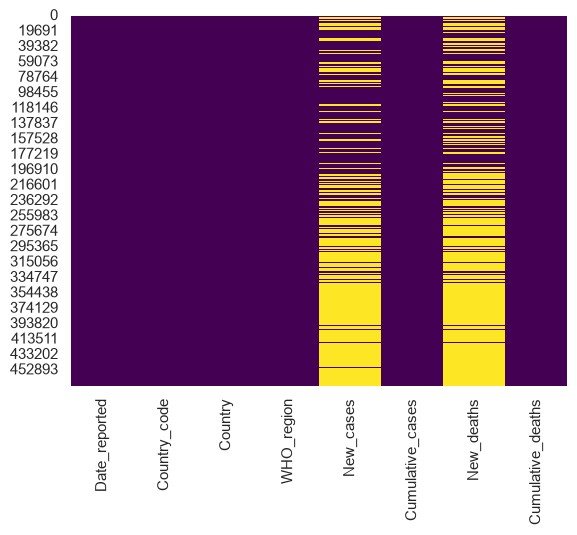

In [16]:
sns.heatmap(full_data.isnull(),cmap='viridis', cbar=False)  

<Axes: >

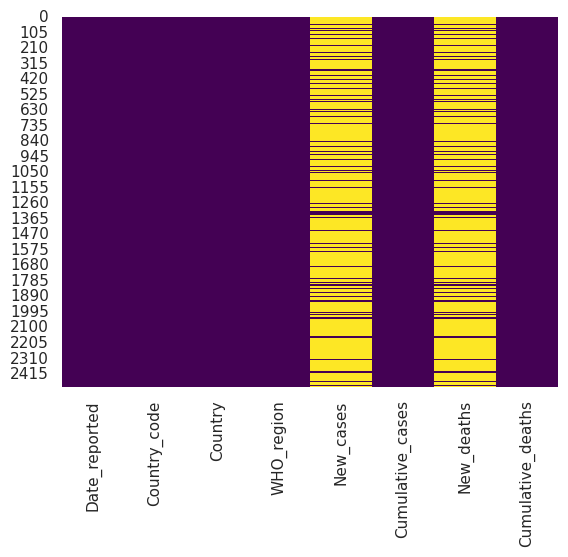

In [12]:
sns.heatmap(full_data.head(2500).isnull(), cmap='viridis', cbar=False)

In [17]:
full_data.columns = full_data.columns.str.strip()

full_data = full_data.drop(columns=['New_deaths'])

print(full_data.columns.tolist())

['Date_reported', 'Country_code', 'Country', 'WHO_region', 'New_cases', 'Cumulative_cases', 'Cumulative_deaths']


In [18]:
full_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 472560 entries, 0 to 472559
Data columns (total 7 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Date_reported      472560 non-null  str    
 1   Country_code       472560 non-null  str    
 2   Country            472560 non-null  str    
 3   WHO_region         472560 non-null  str    
 4   New_cases          209256 non-null  float64
 5   Cumulative_cases   472560 non-null  int64  
 6   Cumulative_deaths  472560 non-null  int64  
dtypes: float64(1), int64(2), str(4)
memory usage: 37.2 MB


<Axes: >

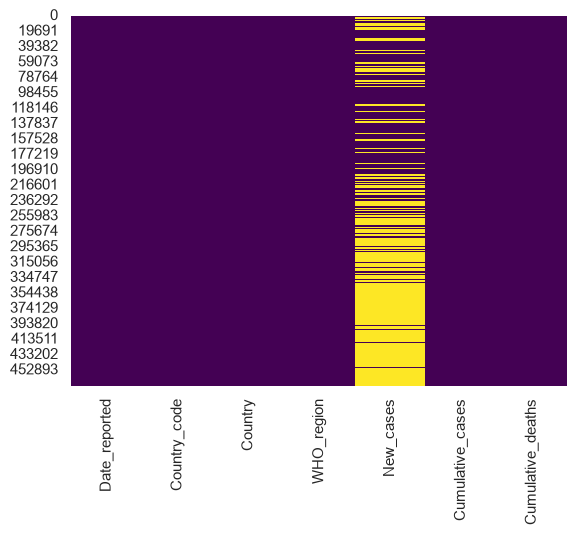

In [19]:
sns.heatmap(full_data.isnull(),cmap='viridis', cbar=False)   #plot heatmap to visualize missing values in the dataset

In [20]:
full_data.sort_values(by='Country').head()

,Date_reported,Country_code,Country,WHO_region,New_cases,Cumulative_cases,Cumulative_deaths
97,01/04/2020,AF,Afghanistan,EMR,NaN,0,0
389,01/05/2020,AF,Afghanistan,EMR,NaN,0,0
577,01/06/2020,AF,Afghanistan,EMR,NaN,0,0
869,01/07/2020,AF,Afghanistan,EMR,NaN,0,0
1057,01/08/2020,AF,Afghanistan,EMR,NaN,0,0


In [21]:
dup_rec=full_data.duplicated()
print('Duplicate Records are =',dup_rec.sum())

Duplicate Records are = 0


In [22]:
numeric_data = full_data.select_dtypes(include=['number'])
Q1=numeric_data.quantile(0.25)
Q3=numeric_data.quantile(0.75)
IQR=Q3-Q1
print('Inter Quartile Range=',IQR)

Inter Quartile Range= New_cases               681.0
Cumulative_cases     636976.0
Cumulative_deaths      7655.0
dtype: float64


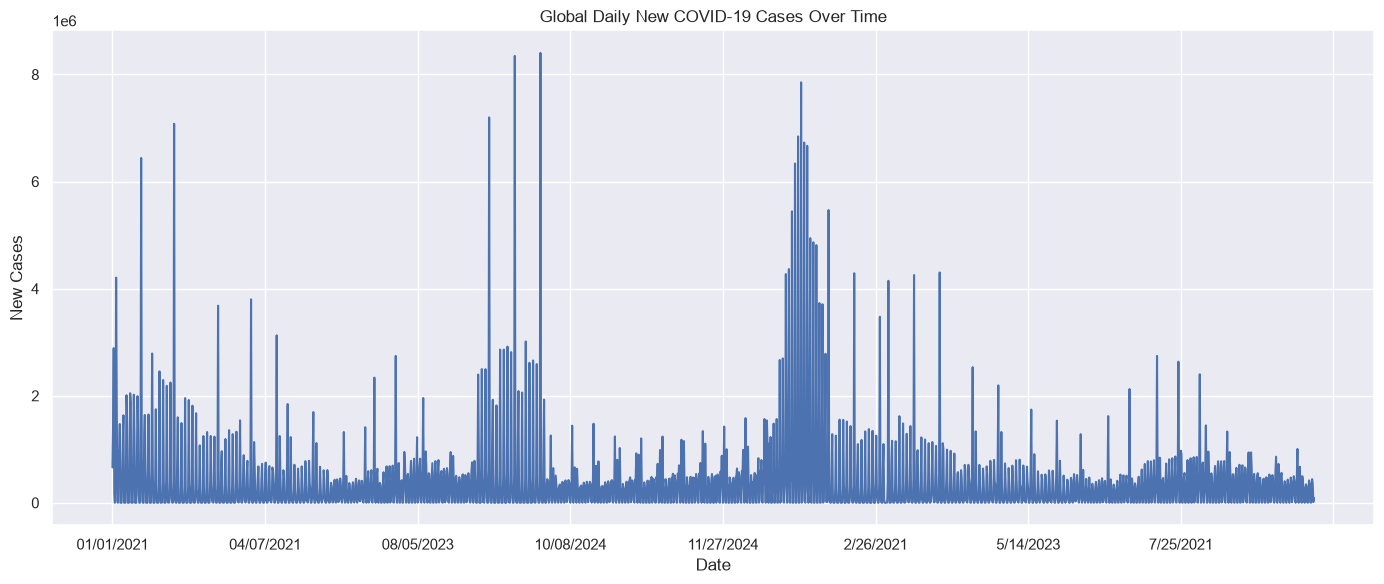

In [23]:
plt.figure(figsize=(14, 6))            # set figure size (width=14, height=6)

full_data.groupby('Date_reported')['New_cases'].sum().plot()  # plot global daily new cases

plt.title('Global Daily New COVID-19 Cases Over Time')  # add title
plt.xlabel('Date')                     # x-axis label
plt.ylabel('New Cases')                # y-axis label
plt.grid(True)                         # show grid
plt.tight_layout()                     # auto-adjust layout
plt.show()                             # display plot


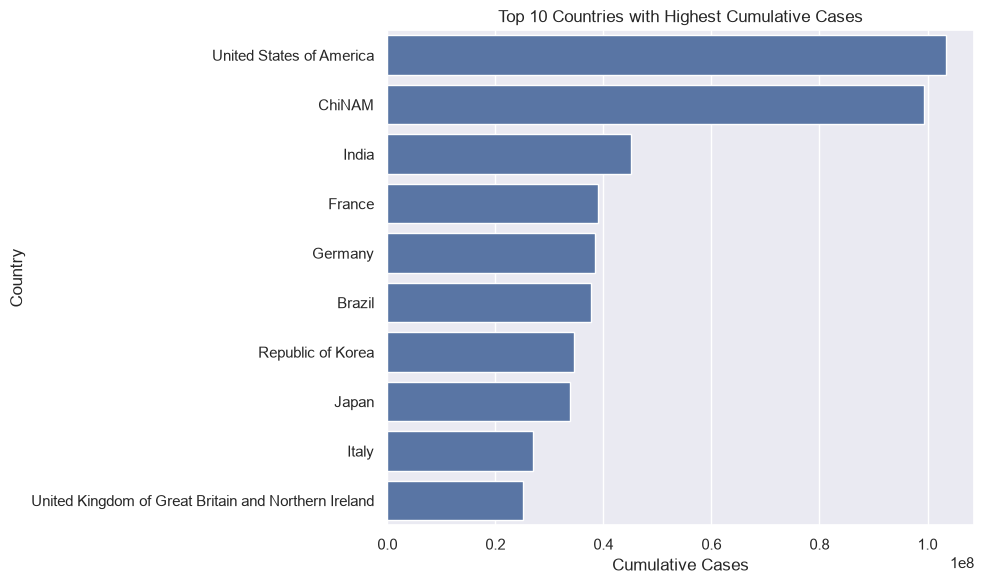

In [24]:
#2. Bar Plot: Top 10 Countries with Highest Total Cases

# Group by country and get the maximum cumulative cases per country
top_10_countries = full_data.groupby('Country')['Cumulative_cases'].max().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))  # set figure size
sns.barplot(x=top_10_countries.values, y=top_10_countries.index)  # basic bar plot without palette
plt.title('Top 10 Countries with Highest Cumulative Cases')  # plot title
plt.xlabel('Cumulative Cases')  # x-axis label
plt.ylabel('Country')  # y-axis label
plt.tight_layout()  # adjust layout
plt.show()  # display plot

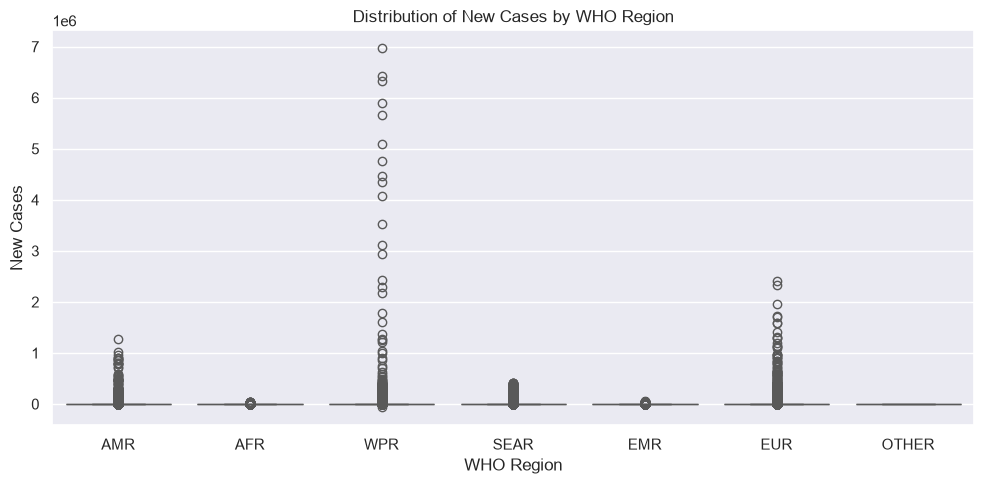

In [25]:
plt.figure(figsize=(10, 5))  # set figure size
sns.boxplot(data=full_data, x='WHO_region', y='New_cases', hue='WHO_region', palette='Set2', legend=False)  # boxplot with hue to avoid warning
plt.title('Distribution of New Cases by WHO Region')  # add title
plt.xlabel('WHO Region')  # x-axis label
plt.ylabel('New Cases')  # y-axis label
plt.tight_layout()  # adjust layout
plt.show()  # display plot

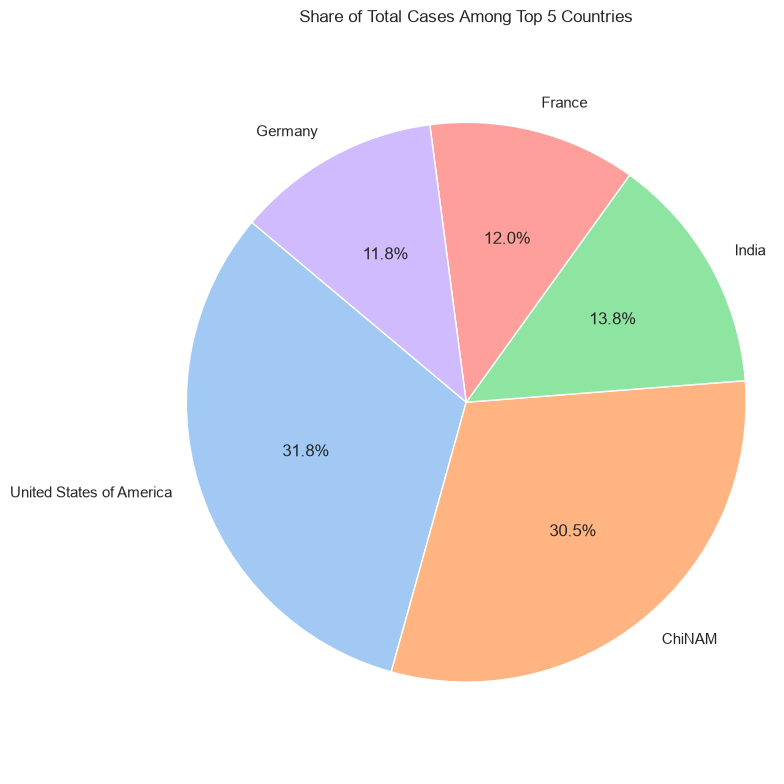

In [26]:
top_5 = full_data.groupby('Country')['Cumulative_cases'].max().sort_values(ascending=False).head(5)  # get top 5 countries by total cases

plt.figure(figsize=(8, 8))  # set figure size (square)
plt.pie(top_5.values, labels=top_5.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette("pastel"))  # create pie chart
plt.title('Share of Total Cases Among Top 5 Countries')  # add title
plt.axis('equal')  # keep pie chart as a circle
plt.tight_layout()  # adjust layout
plt.show()  # display plot

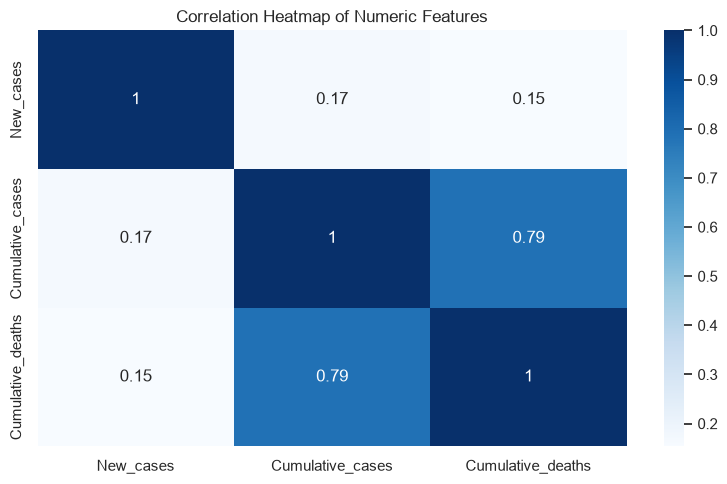

In [27]:
plt.figure(figsize=(8, 5))  # set figure size
sns.heatmap(full_data.select_dtypes(include='number').corr(), annot=True, cmap='Blues')  # plot correlation heatmap for numeric columns
plt.title('Correlation Heatmap of Numeric Features')  # add title
plt.tight_layout()  # adjust layout
plt.show()  # display plot

In [28]:
print(full_data[['Cumulative_cases', 'Cumulative_deaths', 'New_cases']].isnull().sum()) 


Cumulative_cases          0
Cumulative_deaths         0
New_cases            263304
dtype: int64


In [29]:
# Fill missing new_cases using forward fill method
full_data['New_cases'] = full_data['New_cases'].ffill()  # forward fill cleanly

# 2. Select only numeric columns needed for modeling and drop rows with missing values
data = full_data[['Cumulative_cases', 'Cumulative_deaths', 'New_cases']].dropna()  # keep only complete rows

# 3. Define features (X) and target (y)
X = data[['Cumulative_cases', 'Cumulative_deaths']]  # input features
y = data['New_cases']  # target variable

# 4. Split the data into training (80%) and testing (20%) sets
from sklearn.model_selection import train_test_split  # import the split function
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)  # perform the split

In [30]:
# Model Training
# 1. Import libraries
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# 2. Initialize and train the model
lr = LinearRegression()
lr.fit(X_train, y_train)

# 3. Predict on test data
y_pred_lr = lr.predict(X_test)  #save predictions with model-specific name

# 4. Evaluate and save metrics
r2_lr = r2_score(y_test, y_pred_lr)  # R² score
mse_lr = mean_squared_error(y_test, y_pred_lr)  # Mean Squared Error
mae_lr = mean_absolute_error(y_test, y_pred_lr)  # Mean Absolute Error

# 5. Print results
print("Linear Regression Results:")
print(f"R² Score       : {r2_lr:.4f}")
print(f"Mean Squared Error : {mse_lr:.2f}")
print(f"Mean Absolute Error: {mae_lr:.2f}")


Linear Regression Results:
R² Score       : 0.0120
Mean Squared Error : 1193267858.26
Mean Absolute Error: 3736.25


In [31]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

knn = KNeighborsRegressor()
knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_test_scaled)  #save prediction

r2_knn = r2_score(y_test, y_pred_knn)
mse_knn = mean_squared_error(y_test, y_pred_knn)
mae_knn = mean_absolute_error(y_test, y_pred_knn)

print("========== KNN Regressor Results: ==========")
print(f"R² Score       : {r2_knn:.4f}")
print(f"Mean Squared Error : {mse_knn:.2f}")
print(f"Mean Absolute Error: {mae_knn:.2f}")


========== KNN Regressor Results: ==========
R² Score       : 0.3381
Mean Squared Error : 799431275.21
Mean Absolute Error: 2172.58


In [32]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)  # save prediction

r2_dt = r2_score(y_test, y_pred_dt)
mse_dt = mean_squared_error(y_test, y_pred_dt)
mae_dt = mean_absolute_error(y_test, y_pred_dt)

print("Decision Tree Regressor Results:")
print(f"R² Score       : {r2_dt:.4f}")
print(f"Mean Squared Error : {mse_dt:.2f}")
print(f"Mean Absolute Error: {mae_dt:.2f}")


Decision Tree Regressor Results:
R² Score       : 0.3962
Mean Squared Error : 729260056.88
Mean Absolute Error: 2228.17


In [33]:
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (378046, 2)
y_train shape: (378046,)
X_test shape: (94512, 2)
y_test shape: (94512,)


In [34]:
# from sklearn.ensemble import RandomForestRegressor
# from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# rf = RandomForestRegressor(random_state=42)

# rf.fit(X_train, y_train)

# y_pred_rf = rf.predict(X_test)

# r2_rf = r2_score(y_test, y_pred_rf)
# mse_rf = mean_squared_error(y_test, y_pred_rf)
# mae_rf = mean_absolute_error(y_test, y_pred_rf)

# print("Random Forest Regressor Results:")
# print(f"R² Score       : {r2_rf:.4f}")
# print(f"Mean Squared Error : {mse_rf:.2f}")
# print(f"Mean Absolute Error: {mae_rf:.2f}")


from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

print("Starting Random Forest training...")

rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)
print("Model training completed!")

y_pred_rf = rf.predict(X_test)
print("Predictions completed!")

r2_rf = r2_score(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
mae_rf = mean_absolute_error(y_test, y_pred_rf)

print("\nRandom Forest Regressor Results:")
print(f"R² Score              : {r2_rf:.4f}")
print(f"Mean Squared Error    : {mse_rf:.2f}")
print(f"Mean Absolute Error   : {mae_rf:.2f}")


Starting Random Forest training...
Model training completed!
Predictions completed!

Random Forest Regressor Results:
R² Score              : 0.3961
Mean Squared Error    : 729276785.54
Mean Absolute Error   : 2216.89


In [35]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

gb = GradientBoostingRegressor(random_state=42)

gb.fit(X_train, y_train)

y_pred_gb = gb.predict(X_test)

r2_gb = r2_score(y_test, y_pred_gb)
mse_gb = mean_squared_error(y_test, y_pred_gb)
mae_gb = mean_absolute_error(y_test, y_pred_gb)

print("Gradient Boosting Regressor Results:")
print(f"R² Score       : {r2_gb:.4f}")
print(f"Mean Squared Error : {mse_gb:.2f}")
print(f"Mean Absolute Error: {mae_gb:.2f}")


Gradient Boosting Regressor Results:
R² Score       : 0.3531
Mean Squared Error : 781275055.27
Mean Absolute Error: 3062.77


In [36]:
import pandas as pd
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

results = {
    'Model': [
        'Linear Regression',
        'KNN Regressor',
        'Decision Tree',
        'Random Forest',
        'Gradient Boosting'
    ],
    'R2 Score': [
        r2_lr,
        r2_knn,
        r2_dt,
        r2_rf,
        r2_gb
    ],
    'MSE': [
        mse_lr,
        mse_knn,
        mse_dt,
        mse_rf,
        mse_gb
    ],
    'MAE': [
        mae_lr,
        mae_knn,
        mae_dt,
        mae_rf,
        mae_gb
    ]
}

# Convert to DataFrame
results_df = pd.DataFrame(results)

# Sort by best R² score (descending)
results_df = results_df.sort_values(by='R2 Score', ascending=False)

# Display the results
print("Model Performance Comparison:")
print(results_df)


Model Performance Comparison:
               Model  R2 Score           MSE          MAE
2      Decision Tree  0.396160  7.292601e+08  2228.166600
3      Random Forest  0.396146  7.292768e+08  2216.890654
4  Gradient Boosting  0.353091  7.812751e+08  3062.767643
1      KNN Regressor  0.338057  7.994313e+08  2172.576824
0  Linear Regression  0.011954  1.193268e+09  3736.249377


 Best Performing Model: Decision Tree


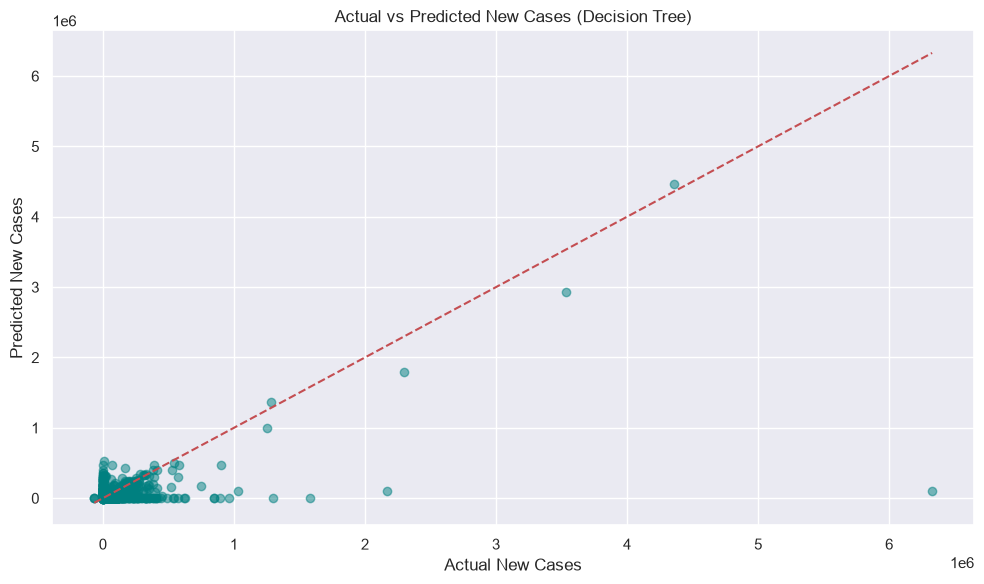

In [37]:
model_predictions = {
    'Linear Regression': y_pred_lr,
    'KNN Regressor': y_pred_knn,
    'Decision Tree': y_pred_dt,
    'Random Forest': y_pred_rf,
    'Gradient Boosting': y_pred_gb
}

best_model_name = results_df.iloc[0]['Model']
print(f" Best Performing Model: {best_model_name}")

best_predictions = model_predictions[best_model_name]

plt.figure(figsize=(10, 6))
plt.scatter(y_test, best_predictions, alpha=0.5, color='teal')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')  # ideal line
plt.title(f'Actual vs Predicted New Cases ({best_model_name})')
plt.xlabel('Actual New Cases')
plt.ylabel('Predicted New Cases')
plt.grid(True)
plt.tight_layout()
plt.show()
